# Week 5 — Improved Models
### Modeling Disagreement in LLM Harm Annotation

---

**Improvements over Week 4:**

| Improvement | Why? |
|---|---|
| **TF-IDF** added to prompt features | Captures specific harmful words (uranium, grooming, exploit) |
| **Interaction terms** added to annotator features | Tests whether annotator profile × prompt type predicts ratings |

**Interaction terms:**

| Term | Hypothesis |
|---|---|
| `Toxicity_Experience × action_Hate_Toxicity` | People who experienced toxicity rate hate content higher |
| `Toxicity_Experience × effect_Psychological` | Toxicity survivors more sensitive to psychological harm |
| `Factor_2 × action_Child_Harm` | Empathic annotators rate child harm prompts higher |
| `Political_conservative × action_Political_Usage` | Conservatives rate political prompts differently |
| `Education_Graduate × value_topic_20` | Educated annotators judge technical/scientific prompts differently |
| `Religion_Important × value_topic_4` | Religious annotators more sensitive to fairness/honesty violations |
| `Religion_Important × action_Manipulation` | Religious annotators rate manipulation prompts higher |

**Note:** Harm_Level is excluded from all models — it is a model-assigned score, not a raw prompt feature.


## 0. Setup

In [23]:
import sys, os, warnings
warnings.filterwarnings('ignore')

def find_repo_root():
    current = os.path.abspath(os.getcwd())
    for _ in range(5):
        if os.path.exists(os.path.join(current, 'data', 'annotations.csv')):
            return current
        current = os.path.dirname(current)
    raise FileNotFoundError("Cannot find repo root.")

REPO_ROOT = find_repo_root()
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully.")

All libraries loaded successfully.


## 1. Load Data

In [24]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

print(f"annotations : {annotations.shape}")
print(f"prompts     : {prompts.shape}")

annotations : (100, 314)
prompts     : (150, 65)


## 2. Define Feature Groups

In [25]:
# ── Prompt features (NO Harm_Level) ──────────────────────────
value_cols  = [c for c in prompts.columns if c.startswith('value_topic_')]
action_cols = [c for c in prompts.columns if c.startswith('action_')]
effect_cols = [c for c in prompts.columns if c.startswith('effect_')]
prompt_features = value_cols + action_cols + effect_cols

# ── Annotator features ────────────────────────────────────────
demo_cols   = ['Gender', 'Age', 'Political_Affiliation', 'Education',
               'Social_Media_Frequency', 'Toxicity_Experience', 'Income',
               'Religion_Importance']
factor_cols = ['Factor_1', 'Factor_2', 'Factor_3']

print(f"Prompt features    : {len(prompt_features)}")
print(f"  value_topic_*    : {len(value_cols)}")
print(f"  action_*         : {len(action_cols)}")
print(f"  effect_*         : {len(effect_cols)}")
print(f"Annotator features : {len(demo_cols) + len(factor_cols)}")

Prompt features    : 62
  value_topic_*    : 39
  action_*         : 16
  effect_*         : 7
Annotator features : 11


## 3. TF-IDF Features

**What is TF-IDF?**
- **TF (Term Frequency):** How often a word appears in this prompt
- **IDF (Inverse Document Frequency):** How rare the word is across all prompts

Words like "the", "how", "what" appear everywhere → low TF-IDF score → ignored
Words like "uranium", "grooming", "exploit" are rare but important → high TF-IDF score → kept

We keep the top 100 most informative words.


In [ ]:
# Extract prompt texts
prompt_texts = prompts.set_index('Question_Index')['Question_Content']

# Fit TF-IDF on all 150 prompts
tfidf = TfidfVectorizer(
    max_features=100,      # keep top 100 words
    stop_words='english',  # remove common words (the, a, is...)
    ngram_range=(1, 2),    # single words AND two-word phrases
)

tfidf_matrix = tfidf.fit_transform(prompts['Question_Content'])
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=[f'tfidf_{w}' for w in tfidf.get_feature_names_out()],
    index=prompts['Question_Index']
).reset_index()

print(f"TF-IDF features: {tfidf_matrix.shape[1]} columns")
print(f"top words: {tfidf.get_feature_names_out()[:20].tolist()}")

TF-IDF features: 100 columns
Example top words: ['000', 'academic', 'according', 'adult', 'alarms', 'avoid', 'based', 'best', 'better', 'candidates', 'cause', 'certain', 'children', 'clients', 'common', 'couple', 'create', 'cultural', 'cut', 'cuts']


## 4. Prepare Data

In [27]:
# ── FORMAT A: Prompt-level (150 rows) for Model 1 and 2 ──────
avg_ratings = {}
for col in rating_cols:
    q_idx = int(col.replace('Rating_', ''))
    avg_ratings[q_idx] = annotations[col].mean()

prompt_df = prompts[['Question_Index'] + prompt_features].copy()
prompt_df['avg_rating'] = prompt_df['Question_Index'].map(avg_ratings)
prompt_df = prompt_df.dropna(subset=['avg_rating'])

# Merge TF-IDF
prompt_df = prompt_df.merge(tfidf_df, on='Question_Index', how='left')
tfidf_cols = [c for c in tfidf_df.columns if c.startswith('tfidf_')]

print(f"Format A (prompt-level): {prompt_df.shape}")

Format A (prompt-level): (150, 164)


In [28]:
# ── FORMAT B: Long format (15,000 rows) for Model 3 and 4 ────
rows = []
for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]
        if pd.isna(rating):
            continue
        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue

        row = {
            'rating'         : rating,
            'question_index' : q_idx,
            'Participant_ID' : ann_row['Participant_ID'],
        }
        for c in prompt_features:
            row[c] = prompt_row[c].values[0]
        for c in demo_cols + factor_cols:
            row[c] = ann_row[c]

        # Add TF-IDF features
        tfidf_row = tfidf_df[tfidf_df['Question_Index'] == q_idx]
        if len(tfidf_row) > 0:
            for c in tfidf_cols:
                row[c] = tfidf_row[c].values[0]
        rows.append(row)

long_df = pd.DataFrame(rows)
long_df_encoded = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)
long_df_encoded = long_df_encoded.fillna(long_df_encoded.median(numeric_only=True))

print(f"Format B (long format): {long_df_encoded.shape}")

Format B (long format): (14725, 198)


## 5. Add Interaction Terms

Each interaction term tests whether the effect of an annotator characteristic
depends on the type of prompt.


In [29]:
# Helper: find encoded column name
def find_col(df, keyword):
    matches = [c for c in df.columns if keyword.lower() in c.lower()]
    return matches[0] if matches else None

# ── Prompt-level (for Model 1, 2) ────────────────────────────
# No annotator interactions for prompt-level models
# (annotator features not available at prompt level)

# ── Long format (for Model 3, 4) ─────────────────────────────
interactions = {
    'Toxicity_x_HateToxicity'    : ('Toxicity_Experience_Often a problem', 'action_Hate_Toxicity'),
    'Toxicity_x_Psychological'   : ('Toxicity_Experience_Often a problem', 'effect_Psychological'),
    'Factor2_x_ChildHarm'        : ('Factor_2',                            'action_Child_Harm'),
    'Conservative_x_Political'   : ('Political_Affiliation_Very conservative', 'action_Political_Usage'),
    'Education_x_Scientific'     : ('Education_Graduate or professional degree (MA, MS, MBA, PhD, JD, MD, DDS etc.)', 'value_topic_20'),
    'Religion_x_Fairness'        : ('Religion_Importance_Very important',  'value_topic_4'),
    'Religion_x_Manipulation'    : ('Religion_Importance_Very important',  'action_Manipulation'),
}

for name, (col_a, col_b) in interactions.items():
    a = find_col(long_df_encoded, col_a.split('_')[0])
    b = find_col(long_df_encoded, col_b)
    if a and b:
        long_df_encoded[name] = long_df_encoded[a] * long_df_encoded[b]
        print(f"  Created: {name}")
    else:
        print(f"  Skipped: {name} (column not found: {col_a} or {col_b})")

interaction_cols = list(interactions.keys())
print(f"\nTotal interaction terms: {len(interaction_cols)}")

  Created: Toxicity_x_HateToxicity
  Created: Toxicity_x_Psychological
  Created: Factor2_x_ChildHarm
  Created: Conservative_x_Political
  Created: Education_x_Scientific
  Created: Religion_x_Fairness
  Created: Religion_x_Manipulation

Total interaction terms: 7


## Model 1 — Prompt Features + TF-IDF → Average Harm

**Improvement:** Added TF-IDF features (top 100 words)
**Using Ridge Regression** to prevent overfitting (150 rows, many features)


In [30]:
all_prompt_features = prompt_features + tfidf_cols
X1 = prompt_df[[c for c in all_prompt_features if c in prompt_df.columns]]
y1 = prompt_df['avg_rating']

# Cross-validation (more reliable than single train/test split for 150 rows)
ridge1 = Ridge(alpha=1.0)
cv_scores1 = cross_val_score(ridge1, X1, y1, cv=5, scoring='r2')

print("Model 1 — Prompt + TF-IDF → Average harm (Ridge, 5-fold CV):")
print(f"  R² per fold : {[round(s,3) for s in cv_scores1]}")
print(f"  Mean R²     : {cv_scores1.mean():.3f}")
print(f"  Std R²      : {cv_scores1.std():.3f}")
print()

# Also fit once for comparison
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42)
ridge1.fit(X1_train, y1_train)
pred1  = ridge1.predict(X1_test)
r2_1   = r2_score(y1_test, pred1)
rmse_1 = np.sqrt(mean_squared_error(y1_test, pred1))
print(f"  Train/test R²   = {r2_1:.3f}")
print(f"  Train/test RMSE = {rmse_1:.2f}")

Model 1 — Prompt + TF-IDF → Average harm (Ridge, 5-fold CV):
  R² per fold : [np.float64(0.382), np.float64(0.043), np.float64(0.088), np.float64(0.009), np.float64(-0.186)]
  Mean R²     : 0.067
  Std R²      : 0.183

  Train/test R²   = 0.048
  Train/test RMSE = 25.35


## Model 2 — Prompt + Annotator Features + TF-IDF → Average Harm


In [31]:
# Aggregate annotator features to prompt level
encoded_demo_cols = [c for c in long_df_encoded.columns
                     if any(c.startswith(d + '_') for d in demo_cols)]
agg_cols = factor_cols + encoded_demo_cols

ann_agg = long_df_encoded.groupby('question_index')[agg_cols].mean().reset_index()
ann_agg.columns = ['question_index'] + [f'mean_{c}' for c in agg_cols]

prompt_df2 = prompt_df.merge(ann_agg, left_on='Question_Index',
                              right_on='question_index', how='left')
prompt_df2 = prompt_df2.dropna()

all_features_2 = [c for c in all_prompt_features if c in prompt_df2.columns] +                  [f'mean_{c}' for c in agg_cols if f'mean_{c}' in prompt_df2.columns]

X2 = prompt_df2[all_features_2]
y2 = prompt_df2['avg_rating']

ridge2    = Ridge(alpha=1.0)
cv_scores2 = cross_val_score(ridge2, X2, y2, cv=5, scoring='r2')

print("Model 2 — Prompt + Annotator + TF-IDF → Average harm (Ridge, 5-fold CV):")
print(f"  Mean R² : {cv_scores2.mean():.3f}")
print(f"  Std R²  : {cv_scores2.std():.3f}")

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)
ridge2.fit(X2_train, y2_train)
pred2  = ridge2.predict(X2_test)
r2_2   = r2_score(y2_test, pred2)
rmse_2 = np.sqrt(mean_squared_error(y2_test, pred2))
print(f"  Train/test R²   = {r2_2:.3f}")
print(f"  Train/test RMSE = {rmse_2:.2f}")

Model 2 — Prompt + Annotator + TF-IDF → Average harm (Ridge, 5-fold CV):
  Mean R² : 0.076
  Std R²  : 0.184
  Train/test R²   = 0.063
  Train/test RMSE = 25.14


## Model 3 — Prompt Features + TF-IDF → Individual + Predicted Average


In [32]:
prompt_feat_cols = [c for c in long_df_encoded.columns
                    if c in prompt_features or c in tfidf_cols]

X3 = long_df_encoded[prompt_feat_cols]
y3 = long_df_encoded['rating']

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42
)

model3 = Ridge(alpha=1.0)
model3.fit(X3_train, y3_train)
pred3  = model3.predict(X3_test)

r2_3_ind   = r2_score(y3_test, pred3)
rmse_3_ind = np.sqrt(mean_squared_error(y3_test, pred3))

# Predicted average
test_df3 = long_df_encoded.loc[y3_test.index].copy()
test_df3['pred'] = pred3
pred_avg3   = test_df3.groupby('question_index')['pred'].mean()
actual_avg3 = test_df3.groupby('question_index')['rating'].mean()
common3     = pred_avg3.index.intersection(actual_avg3.index)
r2_3_avg    = r2_score(actual_avg3[common3], pred_avg3[common3])
rmse_3_avg  = np.sqrt(mean_squared_error(actual_avg3[common3], pred_avg3[common3]))

print("Model 3 — Prompt + TF-IDF → Individual + Predicted Average:")
print(f"  Individual  : R²={r2_3_ind:.3f}  RMSE={rmse_3_ind:.2f}")
print(f"  Pred. Avg   : R²={r2_3_avg:.3f}  RMSE={rmse_3_avg:.2f}")

Model 3 — Prompt + TF-IDF → Individual + Predicted Average:
  Individual  : R²=0.395  RMSE=29.25
  Pred. Avg   : R²=0.913  RMSE=7.26


## Model 4 — Annotator Features + Interaction Terms → Individual + Predicted Average


In [33]:
ann_feat_cols = factor_cols + \
                [c for c in long_df_encoded.columns
                 if any(c.startswith(d + '_') for d in demo_cols)] + \
                [c for c in interaction_cols if c in long_df_encoded.columns]

# Remove duplicates while preserving order
ann_feat_cols = list(dict.fromkeys(ann_feat_cols))

X4 = long_df_encoded[ann_feat_cols]
y4 = long_df_encoded['rating']

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.2, random_state=42
)

model4 = Ridge(alpha=1.0)
model4.fit(X4_train, y4_train)
pred4  = model4.predict(X4_test)

r2_4_ind   = r2_score(y4_test, pred4)
rmse_4_ind = np.sqrt(mean_squared_error(y4_test, pred4))

# Predicted average
test_df4 = long_df_encoded.loc[y4_test.index].copy()
test_df4['pred'] = pred4
pred_avg4   = test_df4.groupby('question_index')['pred'].mean()
actual_avg4 = test_df4.groupby('question_index')['rating'].mean()
common4     = pred_avg4.index.intersection(actual_avg4.index)
r2_4_avg    = r2_score(actual_avg4[common4], pred_avg4[common4])
rmse_4_avg  = np.sqrt(mean_squared_error(actual_avg4[common4], pred_avg4[common4]))

print("Model 4 — Annotator + Interaction Terms → Individual + Predicted Average:")
print(f"  Individual  : R²={r2_4_ind:.3f}  RMSE={rmse_4_ind:.2f}")
print(f"  Pred. Avg   : R²={r2_4_avg:.3f}  RMSE={rmse_4_avg:.2f}")

Model 4 — Annotator + Interaction Terms → Individual + Predicted Average:
  Individual  : R²=0.071  RMSE=36.26
  Pred. Avg   : R²=0.049  RMSE=24.06


## 10. Full Comparison — Week 4 vs Week 5

                                     Model        R²
                 M1: Prompt → Avg (Week 4) -0.679000
          M1: Prompt+TF-IDF → Avg (Week 5)  0.047663
             M2: Prompt+Ann → Avg (Week 4) -3.384000
      M2: Prompt+Ann+TF-IDF → Avg (Week 5)  0.063062
          M3: Prompt → Individual (Week 4)  0.273000
   M3: Prompt+TF-IDF → Individual (Week 5)  0.395366
            M3: Prompt → Pred.Avg (Week 4)  0.626000
     M3: Prompt+TF-IDF → Pred.Avg (Week 5)  0.913432
       M4: Annotator → Individual (Week 4)  0.044000
M4: Ann+Interactions → Individual (Week 5)  0.070587
         M4: Annotator → Pred.Avg (Week 4) -0.006000
  M4: Ann+Interactions → Pred.Avg (Week 5)  0.049291


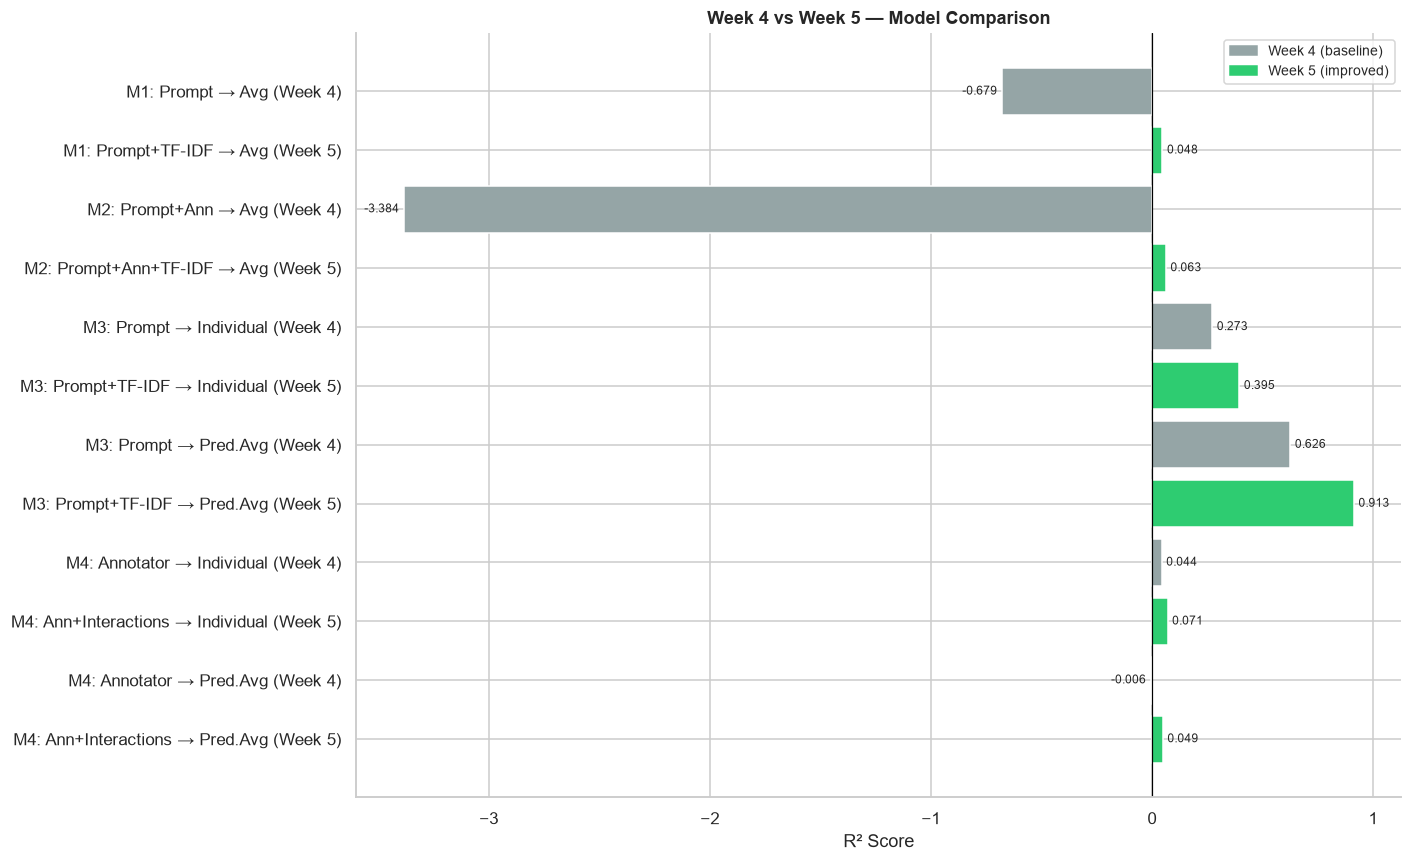

Saved: outputs/fig_week5_comparison.png


In [34]:
results = pd.DataFrame({
    'Model': [
        'M1: Prompt → Avg (Week 4)',
        'M1: Prompt+TF-IDF → Avg (Week 5)',
        'M2: Prompt+Ann → Avg (Week 4)',
        'M2: Prompt+Ann+TF-IDF → Avg (Week 5)',
        'M3: Prompt → Individual (Week 4)',
        'M3: Prompt+TF-IDF → Individual (Week 5)',
        'M3: Prompt → Pred.Avg (Week 4)',
        'M3: Prompt+TF-IDF → Pred.Avg (Week 5)',
        'M4: Annotator → Individual (Week 4)',
        'M4: Ann+Interactions → Individual (Week 5)',
        'M4: Annotator → Pred.Avg (Week 4)',
        'M4: Ann+Interactions → Pred.Avg (Week 5)',
    ],
    'R²': [
        -0.679, r2_1,
        -3.384, r2_2,
        0.273,  r2_3_ind,
        0.626,  r2_3_avg,
        0.044,  r2_4_ind,
        -0.006, r2_4_avg,
    ]
})

print(results.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(13, 8))
colors = ['#95a5a6' if 'Week 4' in m else '#2ecc71' for m in results['Model']]
bars = ax.barh(results['Model'][::-1], results['R²'][::-1],
               color=colors[::-1], edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.3f}" for v in results['R²'][::-1]],
             padding=3, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('R² Score')
ax.set_title('Week 4 vs Week 5 — Model Comparison', fontweight='bold', fontsize=12)

from matplotlib.patches import Patch
legend = [Patch(color='#95a5a6', label='Week 4 (baseline)'),
          Patch(color='#2ecc71', label='Week 5 (improved)')]
ax.legend(handles=legend, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/fig_week5_comparison.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_week5_comparison.png")

## 11. Interaction Term Analysis

Which interaction terms contributed most?
We look at their coefficients in Model 4.


Interaction term coefficients:
                 feature  coefficient
 Toxicity_x_HateToxicity   -64.917161
Toxicity_x_Psychological   -36.444461
Conservative_x_Political   -31.074135
 Religion_x_Manipulation    23.403763
     Factor2_x_ChildHarm    -3.040393
  Education_x_Scientific     2.712696
     Religion_x_Fairness     1.854314


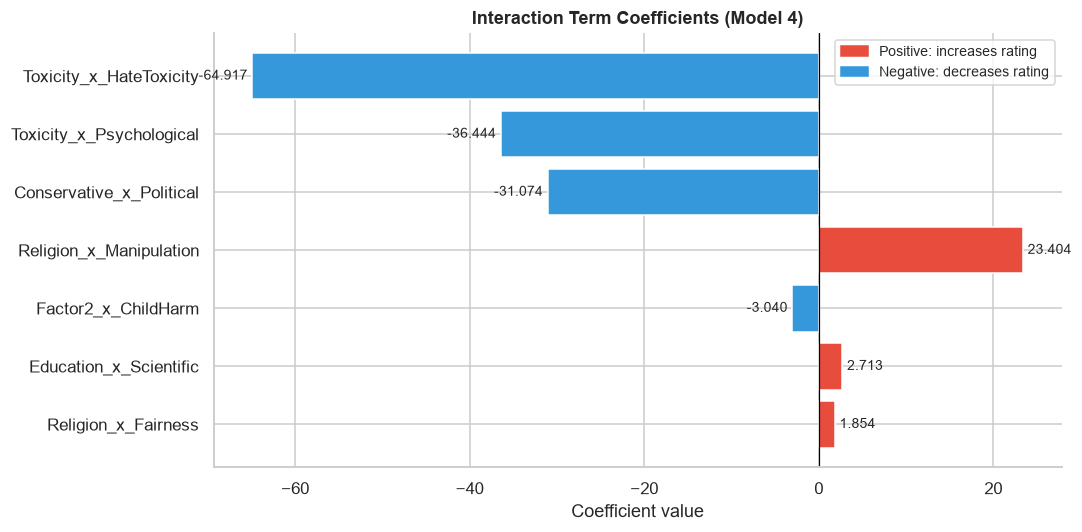

In [35]:
# Get coefficients for interaction terms
coef_df = pd.DataFrame({
    'feature'    : ann_feat_cols,
    'coefficient': model4.coef_
})

# Filter only interaction terms
int_coef = coef_df[coef_df['feature'].isin(interaction_cols)].copy()
int_coef['abs_coef'] = int_coef['coefficient'].abs()
int_coef = int_coef.sort_values('abs_coef', ascending=False)

print("Interaction term coefficients:")
print(int_coef[['feature', 'coefficient']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
colors_int = ['#e74c3c' if c > 0 else '#3498db' for c in int_coef['coefficient']]
bars = ax.barh(int_coef['feature'][::-1], int_coef['coefficient'][::-1],
               color=colors_int[::-1], edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_title('Interaction Term Coefficients (Model 4)', fontweight='bold')
ax.set_xlabel('Coefficient value')
ax.spines[['top', 'right']].set_visible(False)

from matplotlib.patches import Patch
legend = [Patch(color='#e74c3c', label='Positive: increases rating'),
          Patch(color='#3498db', label='Negative: decreases rating')]
ax.legend(handles=legend, fontsize=9)
plt.tight_layout()
plt.savefig("outputs/fig_interaction_terms.png", bbox_inches='tight')
plt.show()

## 12. Summary

### What we improved
1. **TF-IDF** added to prompt models — captures specific harmful/harmless words
2. **Ridge Regression** used instead of Linear Regression — prevents overfitting on small datasets
3. **Cross-validation** used for Model 1 and 2 — more reliable evaluation for 150 rows
4. **Interaction terms** added to Model 4 — tests whether annotator profile × prompt type predicts ratings

### How to interpret interaction terms
- **Positive coefficient** → that combination pushes rating UP
- **Negative coefficient** → that combination pushes rating DOWN
- Example: `Factor_2 × action_Child_Harm` positive → empathic annotators rate child harm prompts higher

### Next steps
- [ ] Mixed-effects model (annotator as random effect)
- [ ] Random Forest with all improved features
- [ ] ELFEN linguistic features


In [36]:
print("Final Summary:")
print(f"  Model 1 Week4: R²=-0.679  →  Week5: R²={r2_1:.3f}")
print(f"  Model 2 Week4: R²=-3.384  →  Week5: R²={r2_2:.3f}")
print(f"  Model 3 Individual Week4: R²=0.273  →  Week5: R²={r2_3_ind:.3f}")
print(f"  Model 3 Pred.Avg  Week4: R²=0.626  →  Week5: R²={r2_3_avg:.3f}")
print(f"  Model 4 Individual Week4: R²=0.044  →  Week5: R²={r2_4_ind:.3f}")
print(f"  Model 4 Pred.Avg  Week4: R²=-0.006 →  Week5: R²={r2_4_avg:.3f}")

print()
print("Output files:")
for f in sorted(os.listdir("outputs")):
    if f.endswith('.png') and 'week5' in f or 'interaction' in f:
        size = os.path.getsize(os.path.join("outputs", f)) / 1024
        print(f"  {f:<50} ({size:.1f} KB)")

Final Summary:
  Model 1 Week4: R²=-0.679  →  Week5: R²=0.048
  Model 2 Week4: R²=-3.384  →  Week5: R²=0.063
  Model 3 Individual Week4: R²=0.273  →  Week5: R²=0.395
  Model 3 Pred.Avg  Week4: R²=0.626  →  Week5: R²=0.913
  Model 4 Individual Week4: R²=0.044  →  Week5: R²=0.071
  Model 4 Pred.Avg  Week4: R²=-0.006 →  Week5: R²=0.049

Output files:
  fig_interaction_terms.png                          (39.6 KB)
  fig_week5_comparison.png                           (73.9 KB)
